<a href="https://colab.research.google.com/github/kazakov7/Computer-vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
print("Menu detector")

Menu detector


In [19]:

# ------------------
# Import Libraries
# ------------------
from google.colab import drive
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np

In [20]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
DATASET_PATH= "/content/drive/MyDrive/food"
CUSTOM_CLASS_MAPPING = {
    "hamburger": "hamburger",
    "hot_dog": "hot_dog",
    "chocolate_cake": "dessert",  # label grouping | class consolidation
    "cheesecake": "dessert",      # label grouping | class consolidation
    "kabob": "kabob",
    "manti": "manti",
    "osh": "osh"
}

CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kabob', 'manti', 'osh']

CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

# print(NUM_CLASSES)
# print(CLASS_TO_IDX)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# 300x400, 512x512 image sizes
# 0 ~ 255
# 0.0 ~ 1.0
# 0.234
# H, W, C => C, H, W | RGB = Red, Green, Blue
# Normalize
# pixel = (pixel - mean) / std

In [22]:
# --------------------
# Custom Dataset Class
# --------------------

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        print('images_length', len(self.images))
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)
        label = self.labels[idx]
        # print('label', label)
        try:
            image = Image.open(img_path).convert('RGB')
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images))
        if self.transform:
            image = self.transform(image)
        return image, label

In [23]:

# --------------------
# Gather and Split Data
# --------------------
all_images = []
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)
    print('class_path:', class_path)
    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue
    for img in os.listdir(class_path):
        if img.endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(class_path, img)
            all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images)
split = int(0.8 * len(all_images))
train_data = all_images[:split]
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

# print('all_images:', all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
img, lbl = dataset[0]

class_path: /content/drive/MyDrive/food/hamburger
class_path: /content/drive/MyDrive/food/hot_dog
class_path: /content/drive/MyDrive/food/chocolate_cake
class_path: /content/drive/MyDrive/food/cheesecake
class_path: /content/drive/MyDrive/food/kabob
class_path: /content/drive/MyDrive/food/manti
class_path: /content/drive/MyDrive/food/osh
images_length 3440
3440


In [24]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [25]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2) #thread | parallel loading for speed
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)


images_length 3440
images_length 3440


In [26]:
# pretrained model
model = mobilenet_v2(weights="IMAGENET1K_V1") # pretrained model | ligthweight | CNN | 1000 class | million
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES) # fine-tuning | backbone | model layer freeze

In [27]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)
model = model.to(device)

device cuda


In [28]:

criterion = nn.CrossEntropyLoss() # Loss Function | '70%' burger, '30%' pilaf
optimizer = optim.Adam(model.parameters(), lr=0.001) # weight
torch.backends.cudnn.benchmark = True # Benchmark Setting | Trick | 10%-20%
# print('criterion:', criterion)
# print('optimizer:', optimizer)

In [12]:
# --------------------
# # Training Loop
# --------------------

NUM_EPOCHS = 10
best_accuracy = 0.0

for epoch in range(NUM_EPOCHS):
    model.train()  # train mode
    running_loss = 0.0  # 70% | 30%Loss | 100%
    for images, labels in train_loader:  # Forward and Backward (Backpropagation)
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()  # zero the gradient
        outputs = model(images)  # Forward Pass | Dog | 5 Classes
        loss = criterion(outputs, labels)  # Calculate Loss
        loss.backward()
        optimizer.step()  # Adam optimizer
        running_loss += loss.item()  # Track Loss

    # Validation
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total  # Calculate Validation Accuracy

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] Loss: {running_loss/len(train_loader):.4f}, Val Accuracy: {val_acc:.2f}%")

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(model.state_dict(), '/content/menu_detector.pth')
        print("Saved new best model!")

Streaming output truncated to the last 5000 lines.
image_path /content/drive/MyDrive/food/chocolate_cake/3412186.jpg
label 2image_path
 /content/drive/MyDrive/food/osh/osh_010.jpg
label 5
image_path /content/drive/MyDrive/food/cheesecake/53831.jpg
label 2
image_path /content/drive/MyDrive/food/cheesecake/1975932.jpg
labelimage_path  2/content/drive/MyDrive/food/hamburger/2928946.jpg

label 0
image_path /content/drive/MyDrive/food/hot_dog/1040579.jpg
labelimage_path  1/content/drive/MyDrive/food/hot_dog/1596571.jpg

label 1
image_path /content/drive/MyDrive/food/cheesecake/3210837.jpg
labelimage_path  2/content/drive/MyDrive/food/chocolate_cake/554548.jpg

label 2
image_path /content/drive/MyDrive/food/hamburger/3308102.jpg
label 0image_path
 /content/drive/MyDrive/food/hot_dog/2201331.jpg
label 1
image_path /content/drive/MyDrive/food/chocolate_cake/511528.jpg
label 2image_path 
/content/drive/MyDrive/food/chocolate_cake/2117495.jpg
label 2
image_path /content/drive/MyDrive/food/chocol

device: cuda
Upload one or more images of your food:


Saving images (1).jpeg to images (1) (2).jpeg


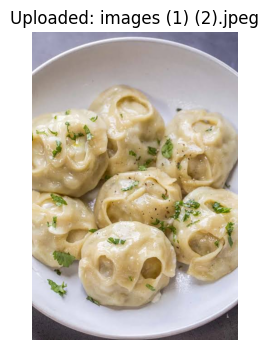

Prediction:
  ✅ manti: 96.37%
  ✅ hot_dog: 2.81%
  ✅ dessert: 0.43%
  ✅ hamburger: 0.35%


In [34]:
# --------------------
# # Required Imports
# --------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# --------------------
# # Define Semantic Classes
# --------------------
CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kabob', 'manti', 'osh']  # Must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# --------------------
# # Transform for Uploaded Images (no augmentations!)
# --------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# --------------------
# # Load Model
# --------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# --------------------
# # Upload & Predict
# --------------------
print("Upload one or more images of your food:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  ✅ {label}: {confidence:.2f}%")